# Constraint Satisfaction Problems (CSPs)

**Agenda**

1. What is a CSP: search vs identification problems, the formal definition, map colouring
2. Constraint graphs and kinds of constraints
3. A CSP as a search problem: the naive incremental approach
4. Backtracking search: commutativity, Sudoku, properties
5. Improving backtracking: MRV and forward checking, degree heuristic, LCV, arc consistency
6. Local search for CSPs: min-conflicts
7. Summary
8. The N-Queens problem (homework)

## Setup: imports and helper code

The helpers draw the map of Australia next to its constraint graph, draw chess boards with queens, and print
Sudoku boards.

You do not need to understand the code. The algorithms in the next sections are what matters.

In [1]:
# The imports used in the rest of the notebook
import random

import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.patches import Polygon

In [2]:
# Helper code that can be skipped

COLOURS = {"red": "#e06666", "green": "#93c47d", "blue": "#6fa8dc", None: "white"}

# rough outlines of the Australian states
AUSTRALIA_SHAPES = {
    "WA": [(-2, 0), (-2, 3), (0, 4.5), (1, 4), (1, 2), (1, 1)],
    "NT": [(1, 4), (2, 5), (3, 4), (3, 2), (1, 2)],
    "Q": [(3, 4), (3, 2), (3.5, 2), (3.5, 1.5), (5.5, 1.5), (4, 5)],
    "SA": [(1, 2), (3.5, 2), (3.5, -1.5), (1, 1)],
    "NSW": [(3.5, -0.5), (5.5, -0.5), (5.5, 1.5), (3.5, 1.5)],
    "V": [(3.5, -1.5), (5.5, -1.5), (5.5, -0.5), (3.5, -0.5)],
    "T": [(4, -2), (5, -2), (5, -3), (4, -3)],
}
GRAPH_POSITIONS = {"WA": (0, 1), "NT": (1.3, 2), "Q": (2.7, 1.7), "SA": (1.5, 0.6), "NSW": (3.1, 0.6),
                   "V": (2.6, -0.5), "T": (2.6, -1.4)}


def draw_coloring(assignment, constraints, title=""):
    violated = {scope for scope, check in constraints
                if all(v in assignment for v in scope) and not check(*(assignment[v] for v in scope))}
    fig, (map_ax, graph_ax) = plt.subplots(1, 2, figsize=(11, 4.5))

    for region, corners in AUSTRALIA_SHAPES.items():
        map_ax.add_patch(Polygon(corners, closed=True, facecolor=COLOURS[assignment.get(region)],
                                 edgecolor="black"))
        xs, ys = zip(*corners)
        map_ax.text(sum(xs) / len(xs), sum(ys) / len(ys), region, ha="center", va="center", fontweight="bold")
    map_ax.set_xlim(-2.5, 6)
    map_ax.set_ylim(-3.5, 5.5)
    map_ax.set_aspect("equal")
    map_ax.axis("off")
    map_ax.set_title("map")

    graph = nx.Graph()
    graph.add_nodes_from(GRAPH_POSITIONS)
    graph.add_edges_from(scope for scope, _ in constraints)
    edges = list(graph.edges)
    is_violated = [(u, v) in violated or (v, u) in violated for u, v in edges]
    nx.draw_networkx_edges(graph, GRAPH_POSITIONS, ax=graph_ax, edgelist=edges,
                           edge_color=["red" if bad else "gray" for bad in is_violated],
                           width=[4 if bad else 1.5 for bad in is_violated])
    nx.draw_networkx_nodes(graph, GRAPH_POSITIONS, ax=graph_ax, node_size=1100, edgecolors="black",
                           node_color=[COLOURS[assignment.get(n)] for n in graph.nodes])
    nx.draw_networkx_labels(graph, GRAPH_POSITIONS, ax=graph_ax, font_size=9, font_weight="bold")
    graph_ax.margins(0.15)
    graph_ax.axis("off")
    graph_ax.set_title("constraint graph" + (" (red edges = violated)" if violated else ""))

    fig.suptitle(title)
    fig.tight_layout()
    plt.close(fig)  # Jupyter would otherwise show the figure twice
    return fig


def draw_queens(queen_rows, title=""):
    # queen_rows[col] = the row of the queen in column col
    n = len(queen_rows)
    fig, ax = plt.subplots(figsize=(4, 4))
    for row in range(n):
        for col in range(n):
            colour = "#f0d9b5" if (row + col) % 2 == 0 else "#b58863"
            ax.add_patch(plt.Rectangle((col, n - 1 - row), 1, 1, color=colour))
    for col, row in enumerate(queen_rows):
        ax.text(col + 0.5, n - 1 - row + 0.5, "♛", ha="center", va="center", fontsize=224 // n)
    ax.set_xlim(0, n)
    ax.set_ylim(0, n)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title)
    plt.close(fig)
    return fig

---

# 1. What is a CSP?

## 1.1 Search problems vs identification problems

- **Standard search problem**: the state is a "black box" - any data structure that supports a goal test, an
  evaluation (a heuristic) and a successor function. The algorithm knows nothing about what is inside a state,
  and the solution of the problem is usually a **path** (a sequence of actions).
- **CSP**: the state has a fixed structure:
    - the **state** is defined by **variables** $X_i$ with **values** from **domains** $D_i$
    - the **goal test** is a set of **constraints** specifying the allowable combinations of values for the variables

Unlike search problems, CSPs only need to identify whether a state is a goal
state or not, with no regard to how we arrived at it. The **path is irrelevant** - only the final assignment
matters.

Because the algorithm can now look *inside* the state (which variables are set, which constraints are violated),
CSPs work for different tasks such as map colouring, Sudoku,
timetabling and N-Queens - only the variables, domains and constraints change.

## 1.2 Formal definition

A CSP is defined by three things:

- **Variables** $X = \{X_1, \dots, X_n\}$ - each takes a single value
- **Domains** $D = \{D_1, \dots, D_n\}$ - $D_i = \{x_1, \dots, x_d\}$ is the set of allowed values for $X_i$
- **Constraints** $C = \{C_1, \dots, C_m\}$ - restrictions on the values of variables, potentially with regard to
  other variables. Each constraint is a pair $\langle \text{scope}, \text{rel} \rangle$:
    - *scope* is the tuple of variables it involves
    - *rel* is a function (predicate) that takes all variables's values in the scope and says whether this combination of values is allowed - for example $X_1 \neq X_2$

An **assignment** gives values to some (or all) of the variables. An assignment is:

- **consistent** if it violates no constraint
- **complete** if every variable has a value

> A **solution** is a **complete and consistent** assignment.

## 1.3 Example: map colouring

We are given a set of colours and must colour a map so that **no two adjacent regions have the same colour**.

- **Variables**: WA, NT, Q, NSW, V, SA, T (the states and territories of Australia)
- **Domains**: $D_i = \{red, green, blue\}$
- **Constraints**: adjacent regions must have different colours, e.g. $WA \neq NT$, or as an explicit list of allowed pairs $(WA, NT) \in \{(red, green), (red, blue), (green, red),
  (green, blue), \dots\}$
- **Solutions** are assignments satisfying all constraints, e.g.
  $\{WA = red, NT = green, Q = red, NSW = green, V = red, SA = blue, T = green\}$

The assignment is a solution: True


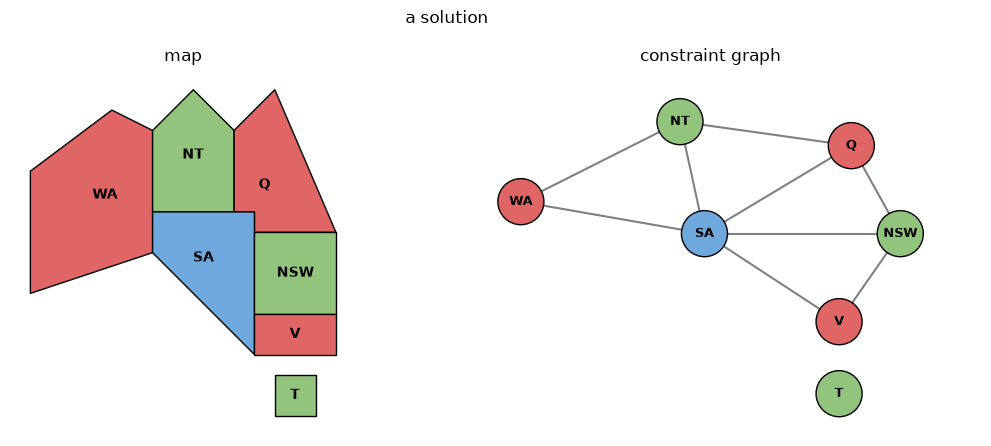

In [3]:
variables = ["WA", "NT", "Q", "NSW", "V", "SA", "T"]
domains = {var: ["red", "green", "blue"] for var in variables}


# predicate
def different(x, y):
    return x != y


# pairs of (scope, check)
constraints = [
    (("WA", "NT"), different), (("WA", "SA"), different), (("NT", "SA"), different), (("NT", "Q"), different),
    (("SA", "Q"), different), (("SA", "NSW"), different), (("SA", "V"), different), (("Q", "NSW"), different),
    (("NSW", "V"), different),
    # T (Tasmania) is an island: it is in no constraint
]


def violated_constraints(assignment, constraints):
    '''Returns a list of violated constraints'''

    return [scope for scope, check in constraints
            if all(var in assignment for var in scope) and # we require all values in the given scope to be set before checking if the constraint is violated
            not check(*(assignment[var] for var in scope))] # we check if the assigned values satisfy the constraint


def is_solution(assignment, variables, constraints):
    complete = all(var in assignment for var in variables)
    consistent = not violated_constraints(assignment, constraints) # we check if the list is empty
    return complete and consistent


assignment = {"WA": "red", "NT": "green", "Q": "red", "NSW": "green", "V": "red", "SA": "blue", "T": "green"}
print("The assignment is a solution:", is_solution(assignment, variables, constraints))

draw_coloring(assignment, constraints, title="a solution")

violated constraints: [('WA', 'SA')]
is a solution: False


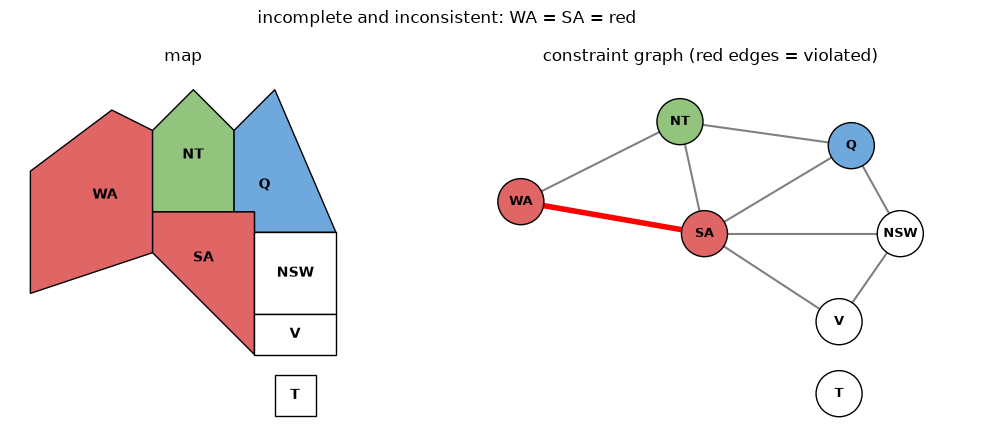

In [4]:
_partial = {"WA": "red", "NT": "green", "SA": "red", "Q": "blue"}
print("violated constraints:", violated_constraints(_partial, constraints))
print("is a solution:", is_solution(_partial, variables, constraints))

draw_coloring(_partial, constraints, title="incomplete and inconsistent: WA = SA = red")

This assignment is **incomplete** (NSW, V, T have no colour) and **inconsistent** (WA and SA are both red), so it
fails twice.

---

# 2. Constraint graphs, constraints and domains

## 2.1 Constraint graph

A **binary CSP** is a CSP where each constraint relates at most two variables. It can be drawn as a
**constraint graph**: the nodes are the variables, and the edges are the constraints between them. For map colouring
we simply draw an edge between every pair of adjacent regions - that is the graph on the right above.


## 2.2 Kinds of constraints

| Kind | Involves | Example | How it is handled |
|---|---|---|---|
| **Unary** | 1 variable | $SA \neq green$ | not drawn in the constraint graph - simply used to shrink the domain of the variable once, before the search |
| **Binary** | 2 variables | $SA \neq WA$ | an edge in the constraint graph |
| **Higher-order** | 3 or more variables | $AllDifferent(X_1, \dots, X_9)$ for a Sudoku row | an extra node connected to all its variables that resembled the constraint |
| **Preferences** (soft constraints) | any | "red is better than green" | often represented by a cost for each assignment → a **constrained optimization problem** |

The first three are **hard constraints** - a solution must satisfy them. Soft constraints only make one solution
better than another, but both can be valid.

A higher-order constraint can often be split into binary ones: $AllDifferent(X_1, \dots, X_k)$ is the same as
$X_i \neq X_j$ for all $i < j$. That is exactly how we model Sudoku later.

---

# 3. A CSP as a search problem - naive incremental search approach

Let us start with the straightforward approach, and then fix it. States are defined by the values assigned so far:

- **Initial state**: the empty assignment $\{\}$
- **Successor function**: assign a value to an unassigned variable that does not conflict with the current
  assignment ⇒ fail if there are no legal assignments (this cannot be fixed by continuing deeper)
- **Goal test**: the current assignment is complete

Observations:

1. This formulation is **the same for all CSPs** - one algorithm solves them all.
2. Every solution appears at **depth exactly $n$** (with $n$ variables) ⇒ use **depth-first search**. BFS would
   only waste memory, since there is nothing to find at the shallower levels.
3. The path is irrelevant, so we can also use a **complete-state formulation** - every state is a full assignment
   (possibly violating constraints), and we try to repair it.
4. The problem: at depth $\ell$ we can choose any of the $n - \ell$ unassigned variables and any of its $d$ values,
   so the branching factor is $b = (n - \ell) d$. The tree has $nd*(n-1)d*(n-2)d* ... *2d*d = n! \cdot d^n$ leaves, even though there are only
   $d^n$ different complete assignments!

For Australia: $7! \cdot 3^7 = 5040 \cdot 2187 = 11{,}022{,}480$ leaves, for only $3^7 = 2187$ different
assignments. Every assignment is reached in $7! = 5040$ different orders.

---

# 4. Backtracking search

## 4.1 The idea - commutativity

Variable assignments are **commutative**: [WA = red, then NT = green] is the same as [NT = green, then WA = red].
So we only need to consider assignments to **a single variable at each node** - fix an order of the variables, and
at depth $\ell$ only assign the $\ell$-th one. Then $b = d$ and there are $d^n$ leaves.


**Depth-first search for CSPs with single-variable assignments is called backtracking search.** It is the basic
uninformed algorithm for CSPs. Compared to plain DFS it has two improvements:

1. **Fix an ordering for variables**, and select values for variables in this order (commutativity, above).
2. When selecting values for a variable, **only select values that do not conflict with any previously assigned
   values**. If no such value exists, **backtrack**: return to the previous variable and change its value.

In [5]:
def backtracking_search(variables, domains, constraints):
    constraints_of = {var: [] for var in variables}  # the constraints each variable is part of
    for scope, check in constraints:
        for var in scope:
            constraints_of[var].append((scope, check))

    assignment = {}

    def consistent(var, value):
        '''check every constraint in which var appears to see if setting var=value remains consistant'''
        assignment[var] = value
        ok = all(check(*(assignment[v] for v in scope))
                 for scope, check in constraints_of[var] if all(v in assignment for v in scope))
        del assignment[var]
        return ok

    def backtrack():
        if len(assignment) == len(variables): # all values are assigned and constraints are satisfied
            return dict(assignment)

        var = next(var for var in variables if var not in assignment)   # the next variable in the fixed variable order

        for value in domains[var]:
            if not consistent(var, value): # this value is not consistant with the already set values of the other variables
                continue

            assignment[var] = value
            result = backtrack()

            if result is not None: #we found a solution
                return result

            del assignment[var]

        return None # Current partial assignments are not consistant, backtrack

    return backtrack()

solution: {'WA': 'red', 'NT': 'green', 'Q': 'red', 'NSW': 'green', 'V': 'red', 'SA': 'blue', 'T': 'red'}


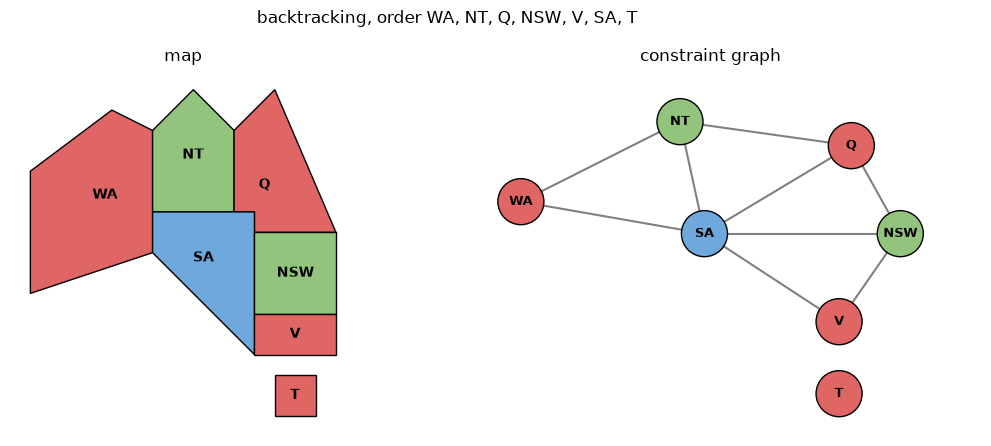

In [6]:
solution = backtracking_search(variables, domains, constraints)
print("solution:", solution)

draw_coloring(solution, constraints, title="backtracking, order WA, NT, Q, NSW, V, SA, T")

This algorithm depends heavily on the variable order, if order is not good, we perform a lot of backtracking.

## 4.2 Sudoku

- **Variables**: the 81 cells $(row, col)$
- **Domains**: $\{1, \dots, 9\}$
- **Constraints**: $AllDifferent$ for every row, every column and every 3×3 box - split into binary $\neq$ constraints
  between every two cells that share a row, a column or a box. Every cell has 20 such neighbours, and there are 810
  constraints in total.

Plain backtracking in row-by-row order solves
it, but needs about **12.7 million assignments** (over a minute in Python), so we do not run it here. Optimizing this is what the next section is about.

## 4.3 Properties of backtracking

Let $n$ be the number of variables and $d$ be the maximum domain size for a given variable.

- **Complete? Yes** for finite domains - it is a DFS over a finite tree of depth $n$, and it only prunes branches
  that already violate a constraint (they can never become a solution).
- **Time? $O(d^n)$** in the worst case - try all possible configurations.
- **Space? $O(n)$** - the current assignment.
- Backtracking alone can solve N-Queens for $n \approx 25$ (this is the task that is given for homework, look at the bottom of this notebook).

---

# 5. Improving backtracking

Since backtracking can perform a lot of assignments until we find a solution, we will try to reduce them by making smarter decisions. The following methods can give huge gains in speed, without knowing anything about the specific problem. They
answer three questions:

1. **Which variable should be assigned next?** → MRV, degree heuristic
2. **Which value should be assigned to a given variable?** → LCV
3. **Can we detect inevitable failure early?** → forward checking, arc consistency

## 5.1 Minimum Remaining Values (MRV) - which variable next?

After every assignment, we can remove the values
that conflict with it from the domains of the unassigned neighbours. Then, we choose the variable with the **fewest legal values** left - the **most constrained variable**. It is the variable
most likely to run out of values and cause a backtrack, so it is best to assign it sooner rather than later: if
it is going to fail, we want to know now, not after many more assignments. MRV is a type of heuristic that tries to tell us which node to assign first such that we are more likely to perform less total searches until we get to the final solution.

If any domain becomes **empty**,
we can terminate this branch right away and backtrack - there is no point continuing, the empty variable can never be assigned. When we backtrack, the removed values are put back. We call this **forward checking**.

Example for Australia: after WA = red and NT = green, SA has only one legal value (blue), so MRV picks SA next.

## 5.2 Degree heuristic - tie-breaker for MRV

When we have multiple variables with equal amount of legal values left, we need a way to choose which one among them should we assign first.  The **degree heuristic** tells us exactly that. It chooses the variable
involved in the **most constraints on the remaining unassigned variables**.

Example for Australia: At the start, all states have three legal values left(red, blue, green), so we use the degree heuristic to break the tie. Following the degree heuristic, we should assign SA first, since it has 5 neighbours - colouring it first constrains the most other variables.

## 5.3 Least Constraining Value (LCV) - which value next?

MRV and degree heuristic give us heuristics that tell us which variable we should assign next. However, we still do not have a heuristic about which value to assign to the chosen variable. This is why we use LCV.

Given a variable, choose the **least constraining value**: the one that rules out the fewest values in the remaining
unassigned neighbors.

Example for Australia: With WA = red and NT = green, setting Q = red leaves 1 value for SA, while Q = blue
leaves 0 - so try red first.

> Note the opposite intuition: for **variables** we fail first (MRV, degree heuristic), for **values** we fail last (LCV). We must
> assign every variable eventually, so we want to find out early if one is impossible. But we need only *one*
> value per variable, so we try the one most likely to lead to a solution first.

LCV requires additional computation (for every value for the current node, check the domains of the other unnasigned neighbors), but it can still
pay off. Combining these heuristics makes **N queens** for $n=1000$ feasible.

## 5.4 Arc consistency

The methods shown so far do not detect **conflicts between two unassigned variables**.

Example for Australia: Let WA = red and Q = green, the feasible values left for NT and SA are both only {blue}. They are neighbours, so this can never work, but we do not notice until one of them
is assigned.

**Arc consistency** is a stronger form of constraint propagation:

- An **arc** $X \to Y$ is a directed version of a binary constraint.
- $X \to Y$ is **consistent** if for **every** value $x$ of $X$ there is **some** allowed value $y$ of $Y$ (a
  "support" for $x$). If there exists a value $x$ of $X$ that has no support $y$, then $x$ can never be part of a solution, so we remove $x$.
- If $X$ loses a value, the arcs **pointing into** $X$ ($Z \to X$) must be checked again, because some value of $Z$
  may have lost its only support.

**Arc consistency** keeps a queue of arcs, that initially are all of our constraints. If we have a binary constraint, for example $NT \ne SA$, we keep both $NT \to SA$ and $SA \to NT$ arcs in the queue. After every assignment of a value to a variable, we repeat the check above until nothing changes any more (no values are removed, which means no contradictions yet, so we can continue assigning), or some domain becomes empty (in which case we backtrack).

---

# 6. Min-conflicts

## 6.1 Iterative algorithms for CSPs

There is another way to approach CSP problems. We can start with some random complete assignment, then iteratively select the most conflicted variable (if multiple such values are most conflicted, select one at random) and reassign
it to the value that violates the fewest constraints, and repeat until no more constraint violations exist (or no improvement in the last M iterations). This approach is called **Min-Conflicts**, and is a type of local search. We can think of Min-conflicts as hill climbing with the number of conflicts as the heuristic.

In [7]:
def min_conflicts(variables, domains, constraints, max_steps=1000, seed=3):
    rng = random.Random(seed)

    constraints_of = {var: [] for var in variables}
    for scope, check in constraints:
        for var in scope:
            constraints_of[var].append((scope, check))

    current = {var: rng.choice(domains[var]) for var in variables} # Set random values from the domains for all variables

    def conflicts(var, value): # number of violated constraints if var had this value
        return sum(1 for scope, check in constraints_of[var]
                   if not check(*(value if v == var else current[v] for v in scope)))

    for step in range(max_steps):
        counts = {var: conflicts(var, current[var]) for var in variables}
        conflicted = [var for var in variables if counts[var] > 0]

        if not conflicted:
            return current, step # no conflicts in current configuration, return it

        # select a random most conflicted variable
        var = rng.choice([v for v in conflicted if counts[v] == max(counts.values())])

        # the number of conflicts we have for each value of the selected variable
        scores = {value: conflicts(var, value) for value in domains[var]}

        # we change the value of the selected variable to be a value that minimizes the resulting conflicts
        current[var] = rng.choice([value for value in domains[var] if scores[value] == min(scores.values())])

    return None, max_steps

solved in 18 steps: {'WA': 'green', 'NT': 'red', 'Q': 'green', 'NSW': 'red', 'V': 'green', 'SA': 'blue', 'T': 'green'}


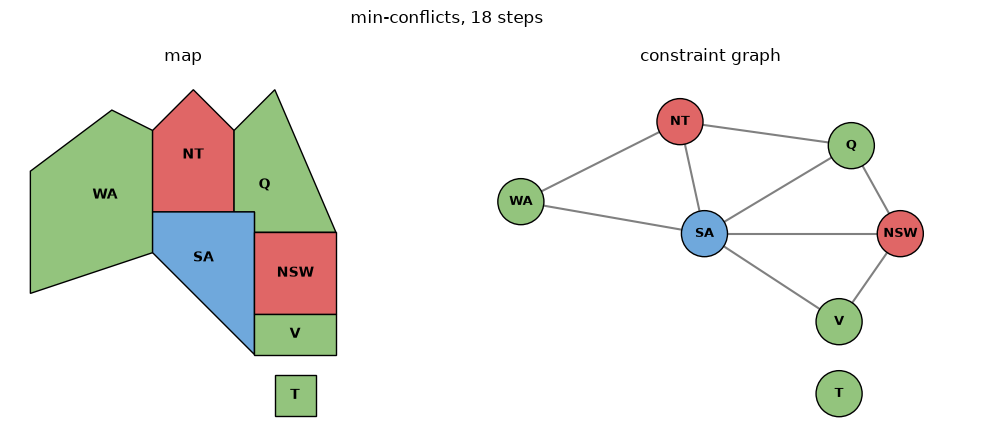

In [8]:
_solution, _steps = min_conflicts(variables, domains, constraints)
print(f"solved in {_steps} steps:", _solution)
draw_coloring(_solution, constraints, title=f"min-conflicts, {_steps} steps")

## 6.2 Performance of min-conflicts

- Given a random initial state, it can solve N-Queens in **almost constant amount of steps for arbitrary $n$** with high
  probability (e.g. $n = 10{,}000{,}000$). The reason: in N-Queens the solutions are densely distributed over the
  state space, so there is almost always a solution close to wherever we start.
- **Space**: $O(n)$ - store only the current assignment.
- It is a local search, so it inherits the problems of hill climbing: it can get stuck in a **local minimum**. It is **not complete**, and it can never prove that there is no solution. The usual fix is **random restarts** - restart the algorithm with a different seed.

# 7. Summary

| | Backtracking search | Min-conflicts |
|---|---|---|
| **Type** | systematic, DFS over partial assignments | local search over complete assignments |
| **Complete?** | Yes | No - can get stuck, used with random restarts |
| **Can prove there is no solution?** | Yes | No |
| **Time** | $O(d^n)$ worst case | no guarantee; for N-Queens almost constant amount of steps in practice |
| **Space** | $O(n)$ | $O(n)$ |
| **Improved by** | MRV + degree, LCV, forward checking, arc consistency | good initialization, randomized tie-breaking, restarts |

# 8. The N-Queens problem

## 8.1 The problem

The **eight queens puzzle** is the problem of placing eight chess queens on an 8×8 chessboard so that no two queens
threaten each other; thus, a solution requires that **no two queens share the same row, column, or diagonal**.
It is an example of the more general **N-Queens** problem of placing $n$ non-attacking queens on an $n \times n$
board, for which solutions exist for all natural numbers $n$ except $n = 2$ and $n = 3$.

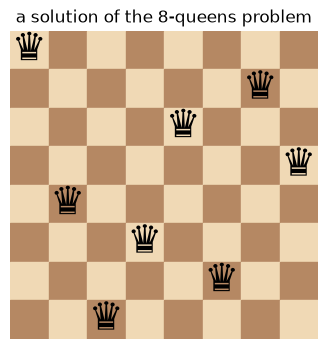

In [9]:
draw_queens([0, 4, 7, 5, 2, 6, 1, 3], title="a solution of the 8-queens problem")

## 8.2 Example: 4-Queens - representing the board

The constraints: one queen per column, one queen per row, at most one queen per diagonal.

- **Question 1**: can we satisfy all these constraints simultaneously? (Yes - for $n = 4$ there are 2 solutions.)
- **Question 2**: can we satisfy *some* of the constraints automatically, just by choosing a good starting state?

The answer to question 2 is the key idea. Placing 4 identical queens on 16 squares gives
$\binom{16}{4} = \frac{16!}{4!\,12!} = 1820$ combinations. But if we say "**queen $i$ is in column $i$**", the
column constraint holds automatically, which leaves
$4^4 = 256$ states. Additionaly, requiring a different row for every queen leaves only $4! = 24$.

## 8.3 Formulation of N Queens as a CSP

**variables**: $Q_0, \dots, Q_{n-1}$ ($Q_i$ is the queen at column $i$)

**domains**: $\{0, \dots, n - 1\}$ (this is the row that we place for queen $Q_i$)

**constraints**: between every two queens, we require them to have different rows, and not be on the same diagonal - we implicitly enforce different columns by definition of the queen variables.

> HINT: Two queens in columns $c_1, c_2$ and rows $r_1, r_2$ are on the same diagonal exactly when $|r_1 - r_2| = |c_1 - c_2|$.

## 8.4 The complete-state formulation

**States**: 4 queens in 4 columns ($4^4 = 256$ states)

**Successor states**: move a queen within its column

**Goal test**: no attacks

**Heuristic**: $h(n)$ = the number of pairs of queens attacking each other

## 8.5 Efficient computation of number of conflicts in $O(1)$

Counting the conflicts of a queen by comparing her with all other queens costs $O(n)$, and doing it for every row
of her column costs $O(n^2)$ per step. For large $n$ that is far too slow. Instead, we keep **counters**:

- `queenPosition[col]` - the row of the queen in column `col` (the state itself)
- `conflictRows[row]` - the number of queens in each row ($n$ entries)
- `conflictPositiveDiagonals[d]` - the number of queens on each "/" diagonal
- `conflictNegativeDiagonals[d]` - the number of queens on each "\\" diagonal

An $n \times n$ board has $2n - 1$ diagonals in each direction. Every square belongs to exactly one of each, and
we need a formula that maps the square to an index $0 \dots 2n - 2$:

- **positive ("/") diagonal**: $row + col$ is the same along the whole diagonal (going up-right, the row decreases
  by 1 while the column increases by 1). It ranges from 0 to $2n - 2$ already.
- **negative ("\\") diagonal**: $col - row$ is the same along the diagonal, but it ranges from $-(n - 1)$ to $n - 1$.
  Adding $n - 1$ shifts it to $0 \dots 2n - 2$: index $= n - 1 - row + col$.

With the counters, the number of other queens attacking a queen at $(row, col)$ is
`conflictRows[row] + conflictPositiveDiagonals[row + col] + conflictNegativeDiagonals[n - 1 - row + col] - 3`
(minus 3, because she counts herself once on each line) - $O(1)$ instead of $O(n)$. Moving a queen updates 6 counters.

## 8.6 Try these tactics if your solution is still slow

**Finding a conflicted queen**: scanning all $n$ queens at every step to find the conflicted ones (or the most conflicted one) is $O(n)$ per step on its own - keep track of them incrementally, or just sample random queens until you hit a conflicted one.

**The initialization**: a random board has a lot of conflicts. Placing all queens in row 0 is the worst start. Much better: place the queens one by one, each on the row with the fewest conflicts
  so far (greedy initialization), or use a pattern based on the knight's move (the slides' "movement of the horse": neighbouring queens are a knight's move apart), which for many $n$ is already a solution or very close to one. With a good initial assignment, the number of repair steps barely grows with $n$ - Russell & Norvig report that min-conflicts solves even the million-queens problem in about 50 steps on average after the initial assignment.